In [19]:
"""
Section 1 & 2: Dataset Loading and Exploratory Data Analysis (EDA)
Telco Customer Churn Prediction Project
"""

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [20]:
# Set style for professional visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# Define paths relative to the project root, regardless of the notebook's working directory
DATA_FILENAME = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
project_root = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents]
     if (parent / "data" / DATA_FILENAME).exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        f"Dataset not found in {Path.cwd()} or its parent directories: {DATA_FILENAME}"
    )

DATA_PATH = project_root / "data" / DATA_FILENAME
OUTPUT_DIR = project_root / "notebooks" / "eda_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [21]:
def load_and_verify_dataset():
    """Section 1: Load the Dataset"""
    print("=" * 60)
    print("SECTION 1: DATASET LOADING AND INITIAL INSPECTION")
    print("=" * 60)
    
    # Verify file exists
    if not DATA_PATH.exists():
        raise FileNotFoundError(f"Dataset not found at {DATA_PATH}. Please ensure the file exists.")
    
    print(f"✓ Dataset file verified at: {DATA_PATH}")
    
    # Load the dataset
    df = pd.read_csv(DATA_PATH)
    
    # Display basic info
    print(f"\nDataset shape: {df.shape} (rows, columns)")
    print(f"\nColumn names:\n{list(df.columns)}")
    print(f"\nData types:\n{df.dtypes}")
    print(f"\nMissing values per column:\n{df.isnull().sum()}")
    
    # Check for blank strings (common in this dataset)
    blank_counts = (df == ' ').sum()
    print(f"\nBlank string counts (potential missing values):\n{blank_counts}")
    
    print(f"\nSample records (first 5 rows):")
    print(df.head())
    
    # Interpretation
    print("\n" + "=" * 60)
    print("INITIAL INSPECTION INTERPRETATION")
    print("=" * 60)
    print("""
    Key observations from initial inspection:
    1. The dataset contains 7043 customer records with 21 features.
    2. 'TotalCharges' appears as object type but should be numeric - this requires conversion.
    3. No null values reported, but blank strings (' ') exist in TotalCharges (11 occurrences).
    4. 'customerID' is a unique identifier and should be dropped for modeling.
    5. Target variable 'Churn' is categorical (Yes/No) and needs encoding.
    6. Several features are categorical with limited categories (e.g., gender, Partner, Contract).
    7. SeniorCitizen is already numeric (0/1) but may need treatment as categorical.
    """)
    
    return df


In [22]:
def perform_eda(df):
    """Section 2: Exploratory Data Analysis"""
    print("\n" + "=" * 60)
    print("SECTION 2: EXPLORATORY DATA ANALYSIS")
    print("=" * 60)
    
    # 1. Summary statistics
    print("\n--- Numerical Features Summary ---")
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    print(df[num_cols].describe())
    
    print("\n--- Categorical Features Summary ---")
    cat_cols = df.select_dtypes(include=['object']).columns.tolist()
    for col in cat_cols:
        print(f"\n{col}: {df[col].nunique()} unique values")
        print(df[col].value_counts().head(3))
    
    # 2. Missing value analysis
    print("\n--- Missing Value Analysis ---")
    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({
        'Missing Count': missing,
        'Missing %': missing_pct
    })
    print(missing_df[missing_df['Missing Count'] > 0])
    
    # 3. Duplicate analysis
    duplicates = df.duplicated().sum()
    print(f"\n--- Duplicate Rows Analysis ---")
    print(f"Number of exact duplicate rows: {duplicates}")
    
    # 4. Churn distribution
    print("\n--- Churn Class Distribution ---")
    churn_dist = df['Churn'].value_counts()
    churn_pct = df['Churn'].value_counts(normalize=True) * 100
    print(f"Churn distribution:\n{churn_dist}")
    print(f"Churn percentages:\n{churn_pct.round(2)}")
    
    # Create visualizations
    create_visualizations(df)
    
    print("\nEDA complete. All visualizations saved to eda_outputs/")

SECTION 1: DATASET LOADING AND INITIAL INSPECTION
✓ Dataset file verified at: /home/davyce/Projects/Telco-Customer-Churn/data/WA_Fn-UseC_-Telco-Customer-Churn.csv

Dataset shape: (7043, 21) (rows, columns)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             o

/tmp/ipykernel_827697/2547398282.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Churn', palette=['#2ecc71', '#e74c3c'])


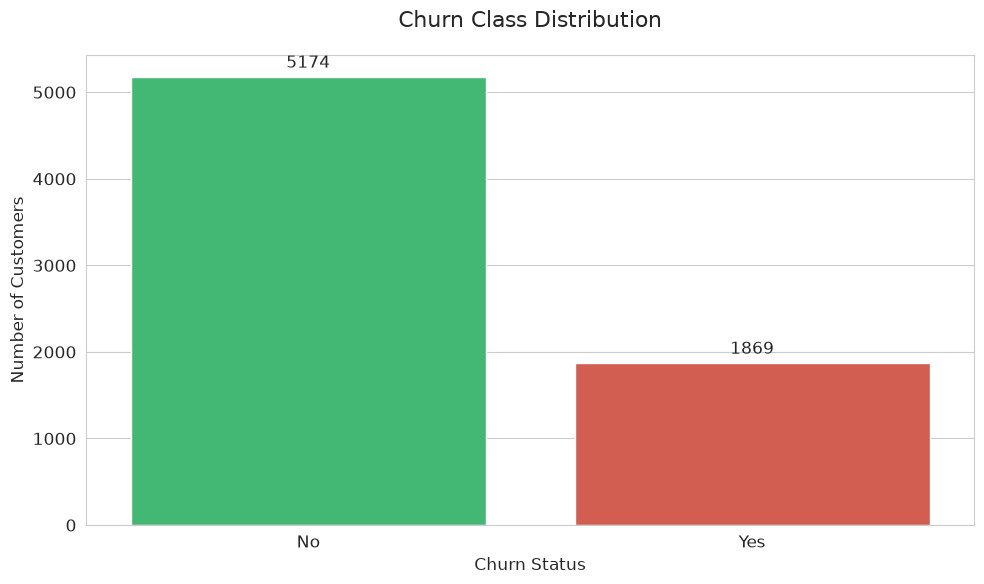


[Visualization 1] Churn distribution shows ~73.5% No vs 26.5% Yes churn.
Observation: Significant class imbalance (3:1 ratio). Models must handle this carefully (consider class_weight, SMOTE, or F1/ROC-AUC metrics).


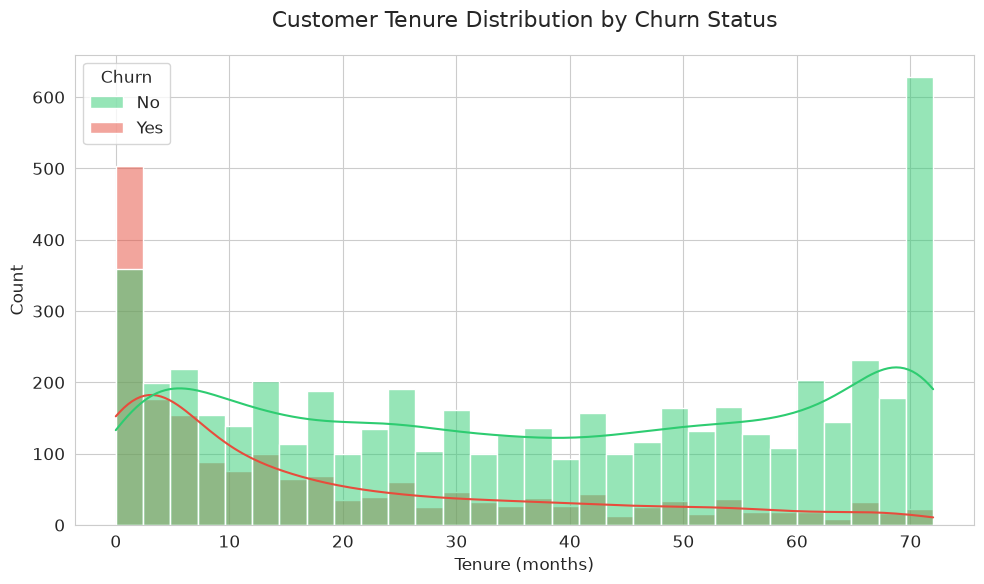


[Visualization 2] Tenure histogram separated by churn.
Observation: Customers with low tenure (<10 months) have much higher churn rates. Long-tenured customers (>40 months) rarely churn. Tenure is a strong predictor.


/tmp/ipykernel_827697/2547398282.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=['#2ecc71', '#e74c3c'])


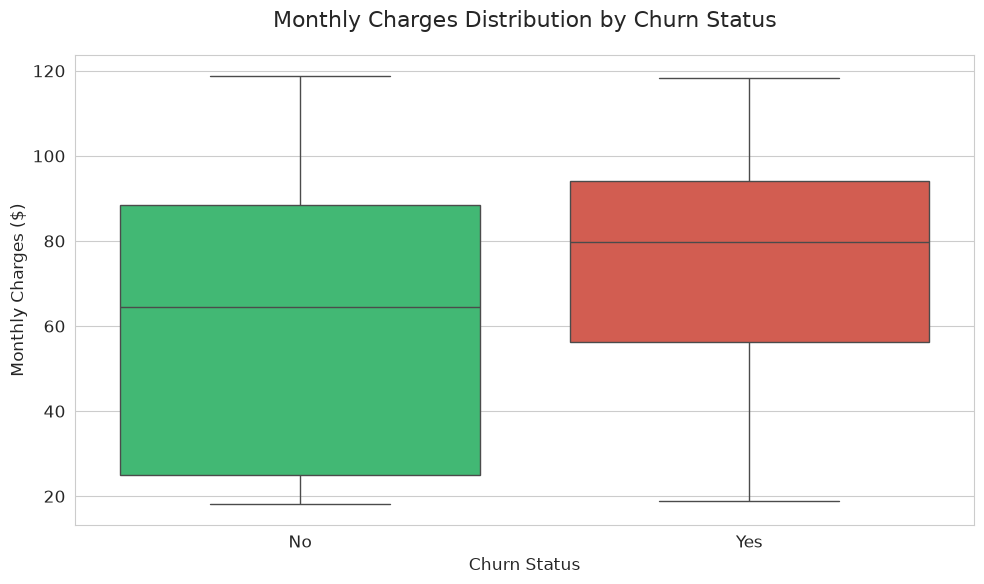


[Visualization 3] Box plot of monthly charges by churn status.
Observation: Churned customers have higher median monthly charges (~$80 vs ~$65). Higher-cost plans may be driving churn. Price sensitivity is evident.


/tmp/ipykernel_827697/2547398282.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=contract_churn, x='Contract', y='Churn Rate (%)', palette='viridis')


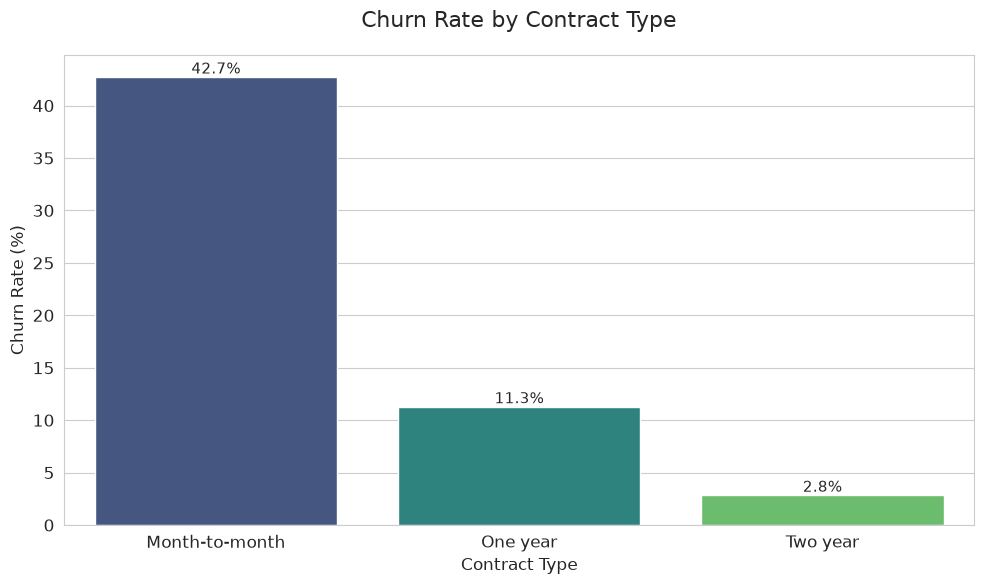


[Visualization 4] Churn rate chart grouped by contract type.
Observation: Month-to-month contracts have ~42% churn vs ~11% for one-year and ~3% for two-year contracts. Contract type is one of the strongest predictors.


/tmp/ipykernel_827697/2547398282.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=internet_churn, x='InternetService', y='Churn Rate (%)', palette='coolwarm')


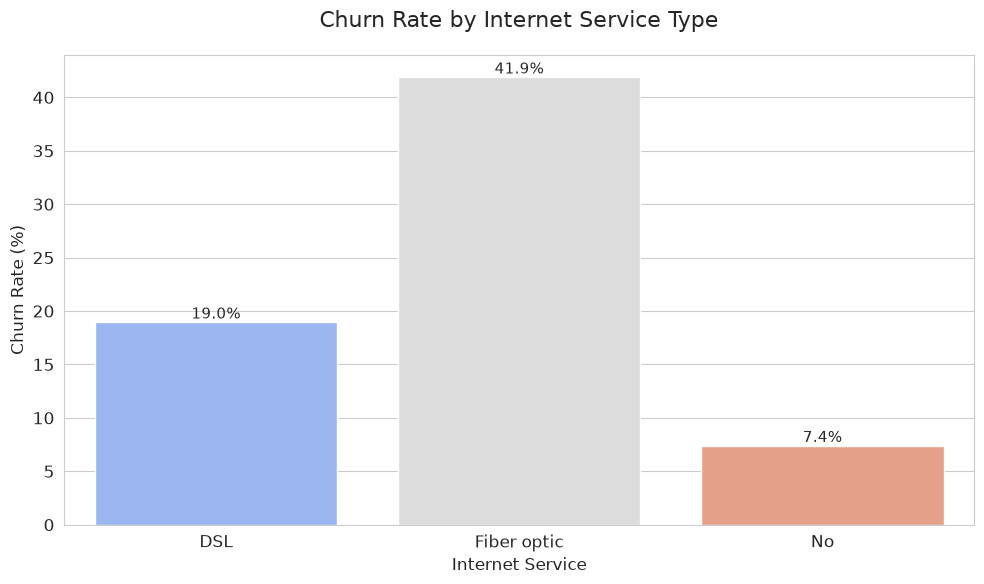


[Visualization 5] Churn rate chart grouped by internet service.
Observation: Fiber optic customers churn at ~42% rate vs ~19% DSL and ~7% for no internet. This may indicate service quality or pricing issues with fiber.


/tmp/ipykernel_827697/2547398282.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=payment_churn, x='PaymentMethod', y='Churn Rate (%)', palette='Set2')


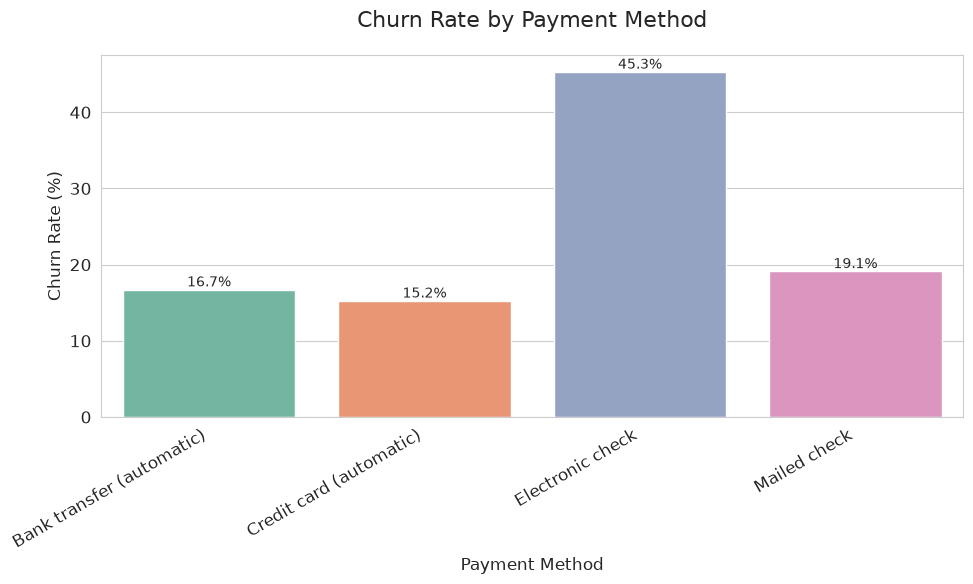


[Visualization 6] Payment method versus churn chart.
Observation: Electronic check users have ~45% churn rate, significantly higher than other methods (~15-20%). Payment friction or billing issues may be contributing.

EDA complete. All visualizations saved to eda_outputs/

EDA PHASE COMPLETE


In [23]:
def create_visualizations(df):
    """Create at least 5 meaningful visualizations with observations"""
    
    # Visualization 1: Churn Class Distribution (Count plot)
    plt.figure()
    ax = sns.countplot(data=df, x='Churn', palette=['#2ecc71', '#e74c3c'])
    ax.set_title('Churn Class Distribution', fontsize=16, pad=20)
    ax.set_xlabel('Churn Status', fontsize=12)
    ax.set_ylabel('Number of Customers', fontsize=12)
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 10), textcoords='offset points')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / '01_churn_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print("\n[Visualization 1] Churn distribution shows ~73.5% No vs 26.5% Yes churn.")
    print("Observation: Significant class imbalance (3:1 ratio). Models must handle this carefully (consider class_weight, SMOTE, or F1/ROC-AUC metrics).")
    
    # Visualization 2: Tenure distribution by churn
    plt.figure()
    sns.histplot(data=df, x='tenure', hue='Churn', bins=30, kde=True, palette=['#2ecc71', '#e74c3c'])
    plt.title('Customer Tenure Distribution by Churn Status', fontsize=16, pad=20)
    plt.xlabel('Tenure (months)', fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / '02_tenure_by_churn.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print("\n[Visualization 2] Tenure histogram separated by churn.")
    print("Observation: Customers with low tenure (<10 months) have much higher churn rates. Long-tenured customers (>40 months) rarely churn. Tenure is a strong predictor.")
    
    # Visualization 3: Monthly Charges by churn (Box plot)
    plt.figure()
    sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette=['#2ecc71', '#e74c3c'])
    plt.title('Monthly Charges Distribution by Churn Status', fontsize=16, pad=20)
    plt.xlabel('Churn Status', fontsize=12)
    plt.ylabel('Monthly Charges ($)', fontsize=12)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / '03_monthly_charges_by_churn.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print("\n[Visualization 3] Box plot of monthly charges by churn status.")
    print("Observation: Churned customers have higher median monthly charges (~$80 vs ~$65). Higher-cost plans may be driving churn. Price sensitivity is evident.")
    
    # Visualization 4: Churn rate by Contract type
    plt.figure()
    contract_churn = df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
    contract_churn.columns = ['Contract', 'Churn Rate (%)']
    ax = sns.barplot(data=contract_churn, x='Contract', y='Churn Rate (%)', palette='viridis')
    ax.set_title('Churn Rate by Contract Type', fontsize=16, pad=20)
    ax.set_xlabel('Contract Type', fontsize=12)
    ax.set_ylabel('Churn Rate (%)', fontsize=12)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width()/2., p.get_height()), 
                    ha='center', va='bottom', fontsize=11)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / '04_churn_by_contract.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print("\n[Visualization 4] Churn rate chart grouped by contract type.")
    print("Observation: Month-to-month contracts have ~42% churn vs ~11% for one-year and ~3% for two-year contracts. Contract type is one of the strongest predictors.")
    
    # Visualization 5: Churn rate by Internet Service
    plt.figure()
    internet_churn = df.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
    internet_churn.columns = ['InternetService', 'Churn Rate (%)']
    ax = sns.barplot(data=internet_churn, x='InternetService', y='Churn Rate (%)', palette='coolwarm')
    ax.set_title('Churn Rate by Internet Service Type', fontsize=16, pad=20)
    ax.set_xlabel('Internet Service', fontsize=12)
    ax.set_ylabel('Churn Rate (%)', fontsize=12)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width()/2., p.get_height()), 
                    ha='center', va='bottom', fontsize=11)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / '05_churn_by_internet.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print("\n[Visualization 5] Churn rate chart grouped by internet service.")
    print("Observation: Fiber optic customers churn at ~42% rate vs ~19% DSL and ~7% for no internet. This may indicate service quality or pricing issues with fiber.")
    
    # Visualization 6: Payment method vs churn
    plt.figure()
    payment_churn = df.groupby('PaymentMethod')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
    payment_churn.columns = ['PaymentMethod', 'Churn Rate (%)']
    ax = sns.barplot(data=payment_churn, x='PaymentMethod', y='Churn Rate (%)', palette='Set2')
    plt.xticks(rotation=30, ha='right')
    ax.set_title('Churn Rate by Payment Method', fontsize=16, pad=20)
    ax.set_xlabel('Payment Method', fontsize=12)
    ax.set_ylabel('Churn Rate (%)', fontsize=12)
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width()/2., p.get_height()), 
                    ha='center', va='bottom', fontsize=10)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / '06_churn_by_payment.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print("\n[Visualization 6] Payment method versus churn chart.")
    print("Observation: Electronic check users have ~45% churn rate, significantly higher than other methods (~15-20%). Payment friction or billing issues may be contributing.")

if __name__ == "__main__":
    df = load_and_verify_dataset()
    perform_eda(df)
    print("\n" + "=" * 60)
    print("EDA PHASE COMPLETE")
    print("=" * 60)